# 03 - Spherical geometry: tangent planes, rotations, validation

All projection code is in `geometry/`; this notebook demonstrates and *validates* it before any experiment is trusted.

In [1]:
import os, sys, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
RES = 'results/midas_dpt_hybrid_synthetic'   # change to e.g. results/dap_stanford2d3d after running DAP
REP = os.path.join(RES, 'report_align-all')
def show(p, w=900):
    p = os.path.join(RES, p) if not os.path.exists(p) else p
    display(Image(filename=p, width=w)) if os.path.exists(p) else print('missing', p)

## Validation (exact maths and interpolation error)

In [2]:
from geometry.validation import run_all
g = run_all(save_path=None)
display(Markdown('**Point level** (sphere -> ERP -> sphere -> tangent -> 3D -> ERP, known depth)'))
display(pd.DataFrame(g['point_level']).T)
display(Markdown('**Image level** (bilinear resampling of an analytic field; plane depth z->range check)'))
display(pd.DataFrame(g['image_level']).T[['erp2tan_mean_rel_err','roundtrip_mean_rel_err','roundtrip_max_rel_err',
                                          'plane_range_max_rel_err','plane_range_err_if_z_used_as_range_max']])
display(Markdown('**Rotations**'))
pd.DataFrame(g['rotation']).T

**Point level** (sphere -> ERP -> sphere -> tangent -> 3D -> ERP, known depth)

,max_angle_err_deg,max_pixel_err,max_rel_depth_err
"centre (0,0)",5.573916e-14,1.136868e-13,1.093819e-15
"equator (120,0)",4.980895e-14,1.136868e-13,1.255888e-15
"mid-lat (45,35)",5.564267e-14,2.273737e-13,1.123926e-15
"high-lat (-60,65)",9.210045e-13,2.614797e-12,5.359307e-15
"near-pole (10,85)",3.163233e-13,8.322232e-13,6.739473e-16
"north pole (0,90)",1.192895e-12,9.410250e-13,6.356040e-16
"south pole (0,-90)",4.037148e-13,1.364242e-12,7.300121e-16
"wrap (179,20)",5.238268e-14,2.273737e-13,1.137059e-15
"wrap (-178,-50)",6.288487e-13,1.082867e-11,7.117637e-15


**Image level** (bilinear resampling of an analytic field; plane depth z->range check)

,erp2tan_mean_rel_err,roundtrip_mean_rel_err,roundtrip_max_rel_err,plane_range_max_rel_err,plane_range_err_if_z_used_as_range_max
"centre (0,0)",2.373309e-06,0.000003,0.000390,0.001114,0.421365
"equator (120,0)",1.423817e-06,0.000002,0.000326,0.001271,0.420190
"mid-lat (45,35)",1.651876e-06,0.000002,0.000522,0.001250,0.421624
"high-lat (-60,65)",1.235008e-06,0.000002,0.000575,0.001284,0.420917
"near-pole (10,85)",1.105184e-06,0.000002,0.000508,0.001261,0.420737
"north pole (0,90)",1.065621e-06,0.000002,0.000530,0.001185,0.416691
"south pole (0,-90)",8.310300e-07,0.000001,0.000592,0.001185,0.416691
"wrap (179,20)",2.971156e-06,0.000004,0.000551,0.001272,0.420833
"wrap (-178,-50)",2.211194e-06,0.000002,0.000485,0.001287,0.420126


**Rotations**

,value,rotate_mean_rel_err,rotate_max_rel_err,roundtrip_mean_rel_err,roundtrip_max_rel_err,roundtrip_mean_rel_err_|lat|>75
yaw90_vs_column_roll_max_abs,4.440892e-15,NaN,NaN,NaN,NaN,NaN
yaw0_pitch90,NaN,0.000002,0.000016,0.000003,0.000027,0.000002
yaw0_pitch-90,NaN,0.000002,0.000016,0.000003,0.000027,0.000002
yaw30_pitch45,NaN,0.000002,0.000016,0.000003,0.000027,0.000001
yaw0_pitch60,NaN,0.000002,0.000016,0.000003,0.000024,0.000002
yaw90_pitch90,NaN,0.000002,0.000016,0.000003,0.000027,0.000002


## Tangent views of the polar caps

TangentPlane(lon_deg=0.0, lat_deg=90.0, fov_deg=74.0, size=256, roll_deg=0.0)
TangentPlane(lon_deg=-90.0, lat_deg=63.0, fov_deg=101.71828995311843, size=256, roll_deg=0.0)
TangentPlane(lon_deg=90.0, lat_deg=63.0, fov_deg=101.71828995311843, size=256, roll_deg=0.0)


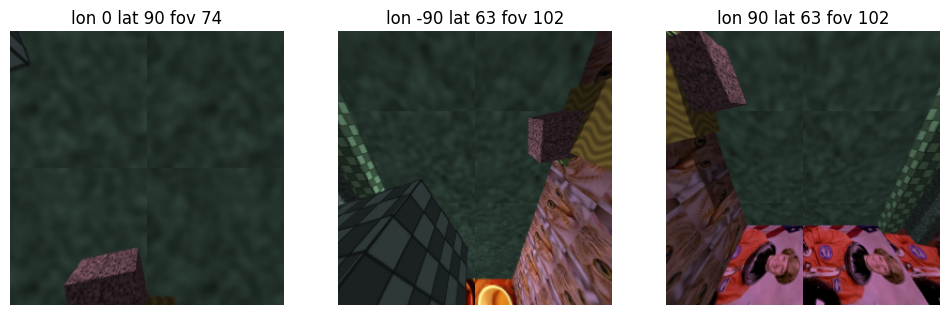

In [3]:
from experiments.common import load_config, make_dataset
from geometry.tangent_plane import polar_tangent_layout, erp_to_tangent, tangent_to_erp
cfg = load_config('configs/default.yaml'); s = make_dataset(cfg)[0]
planes = polar_tangent_layout(45, views_per_pole=3, size=256)
for p in planes[:3]: print(p)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, p in zip(ax, planes[:3]):
    a.imshow(erp_to_tangent(s.rgb.astype(np.float32), p).astype(np.uint8)); a.set_title(f'lon {p.lon_deg:.0f} lat {p.lat_deg:.0f} fov {p.fov_deg:.0f}'); a.axis('off')
plt.show()

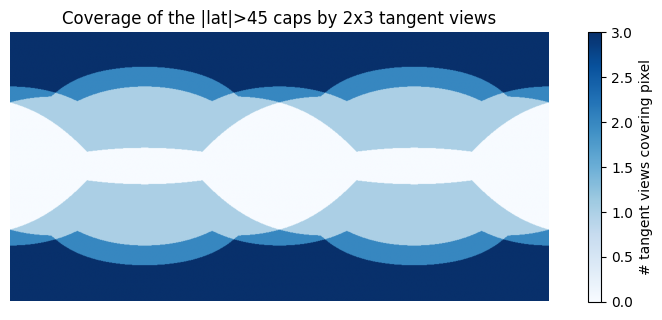

In [4]:
cover = np.zeros(s.depth.shape, int)
for p in planes: cover += tangent_to_erp(np.ones((p.size, p.size)), p, *s.depth.shape).valid
plt.figure(figsize=(10, 3.5)); plt.imshow(cover, cmap='Blues'); plt.colorbar(label='# tangent views covering pixel')
plt.title('Coverage of the |lat|>45 caps by 2x3 tangent views'); plt.axis('off'); plt.show()

## Spherical rotation (not a pixel shift)
Pitch +90 deg brings BOTH poles onto the equator (north at the front, south at the back).

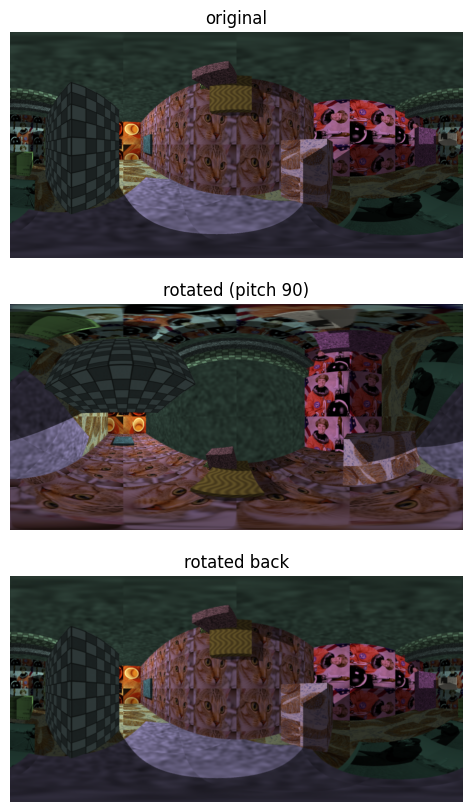

In [5]:
from geometry.erp_projection import rotate_erp
from geometry.spherical import rotation_from_ypr
R = rotation_from_ypr(0, 90, 0)
rot = rotate_erp(s.rgb.astype(np.float32), R).astype(np.uint8)
back = rotate_erp(rot.astype(np.float32), R.T).astype(np.uint8)
fig, ax = plt.subplots(3, 1, figsize=(10, 10))
for a, im, t in zip(ax, [s.rgb, rot, back], ['original', 'rotated (pitch 90)', 'rotated back']): a.imshow(im); a.set_title(t); a.axis('off')
plt.show()

## The full tangent pipeline on one view (from the experiment run)

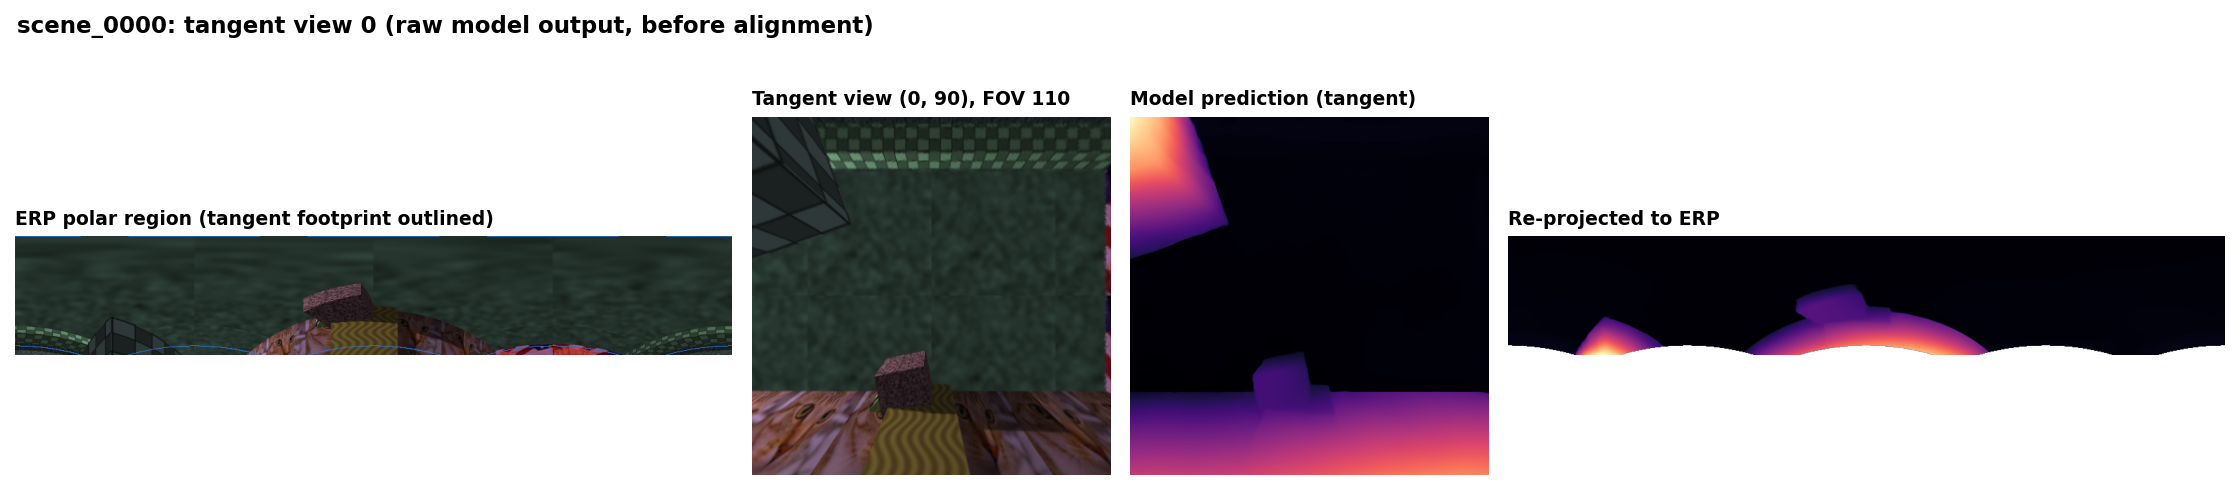

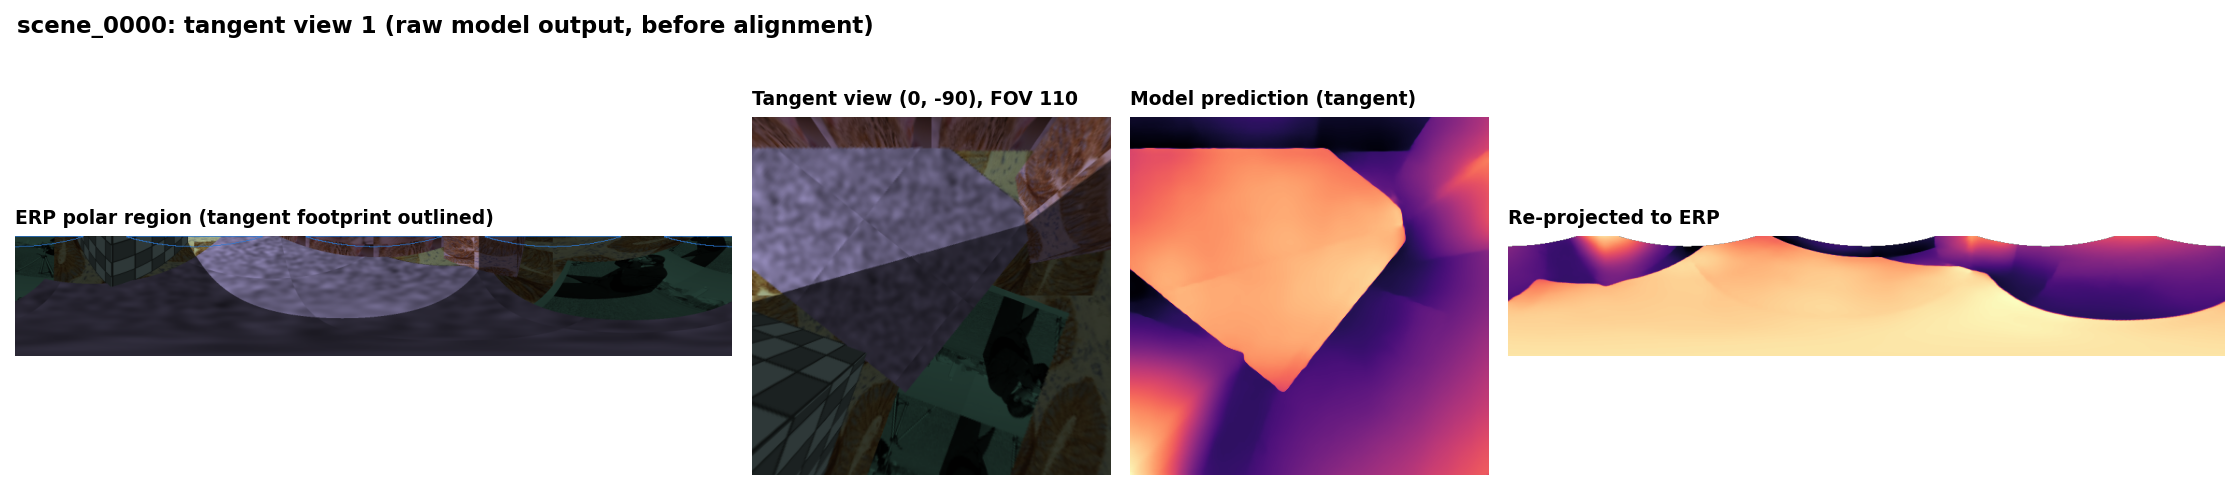

In [6]:
import glob
for p in sorted(glob.glob(os.path.join(RES, 'qualitative', 'tangent_view_*.png')))[:2]: show(p, 1100)